In [11]:
import matplotlib.pyplot as plt
import numpy as np

In [21]:
# making a class
class FDMSolver:

  def __init__(self, n=4000):
    self.n = n               # defineing no of grid for for H matrix

  def _build_H_matrix(self, m, dr, h_bar):
    A = np.zeros((self.n, self.n))
    C = -1 * ((h_bar ** 2) / (2 * m * (dr ** 2)))
    for i in range(self.n):
      for j in range(self.n):
        if i == j:
          A[i, j] = -2
        elif abs(i - j) == 1:
          A[i, j] = 1
    H = A * C
    return H

  def solve_case(self, case_name, **kwargs):
    case = case_name.lower()
    params = kwargs
   # bulding differnet cases
      
    # UNIT 2 CASES
    if case == "box":
      L = params.get("L", 10.0)  # Å
      m = params.get("m", 0.511e6)  # eV/c^2
      h_bar = params.get("h_bar", 1973.27)
      dr = L / (self.n + 1)
      self.r = np.linspace(dr, L - dr, self.n)

      H = self._build_H_matrix(m, dr, h_bar)
      V = np.diag(np.zeros(self.n))
      D = np.diag(np.zeros(self.n))

    elif case == "finite_well":
      # Unit 2: Particle in a finite potential well
      x_range = params.get(
          "x_range", 10.0
      )  # total spatial span [-x_range, x_range]
      m = params.get("m", 0.511e6)  # eV/c^2
      h_bar = params.get("h_bar", 1973.27)
      V0 = params.get("V0", 50.0)  # Barrier height outside (eV)
      a = params.get("well_width", 4.0)  # Width of the well (Å)

      dr = (2 * x_range) / (self.n + 1)
      self.r = np.linspace(-x_range + dr, x_range - dr, self.n)

      H = self._build_H_matrix(m, dr, h_bar)
      # Potential is 0 inside the well (-a/2 to a/2) and V0 outside
      # np.where(condition,if,elif)
      V_values = np.where(                                    
          (self.r >= -a / 2) & (self.r <= a / 2), 0.0, V0
      )
      V = np.diag(V_values)
      D = np.diag(np.zeros(self.n))

    elif case == "harmonic":
      x_range = params.get("x_range", 5.0)
      m = params.get("m", 0.511e6)
      h_bar = params.get("h_bar", 1973.27)
      omega = params.get("omega", 0.05)
      dr = (2 * x_range) / (self.n + 1)
      self.r = np.linspace(-x_range + dr, x_range - dr, self.n)

      H = self._build_H_matrix(m, dr, h_bar)
      V = np.diag(0.5 * m * (omega ** 2) * (self.r ** 2))
      D = np.diag(np.zeros(self.n))

    # UNIT 3 CASES
    elif case == "hydrogen":
      R_max = params.get("R_max", 20.0)
      m = params.get("m", 0.511e6)
      h_bar = params.get("h_bar", 1973.27)

      dr = R_max / (self.n + 1)
      self.r = np.linspace(dr, R_max - dr, self.n)
     
      e_sq = 3.795 ** 2
      l = params.get("l", 0)

      H = self._build_H_matrix(m, dr, h_bar)
      V = np.diag(-e_sq / self.r)
      D = np.diag(((h_bar ** 2) * l * (l + 1)) / (2 * m * (self.r ** 2)))

    elif case == "screened_coulomb":
      R_max = params.get("R_max", 20.0)
      a = params.get("a", 3.0)
      m = params.get("m", 0.511e6)
      h_bar = params.get("h_bar", 1973.27)
        
      dr = R_max / (self.n + 1)
      self.r = np.linspace(dr, R_max - dr, self.n)
        
      e_sq = 3.795 ** 2
      l = params.get("l", 0)

      H = self._build_H_matrix(m, dr, h_bar)
      V = np.diag(-(e_sq / self.r) * np.exp(-a * self.r))
      D = np.diag(((h_bar ** 2) * l * (l + 1)) / (2 * m * (self.r ** 2)))

    # UNIT 4 CASES 
    elif case == "anharmonic":
      R_max = params.get("R_max", 5.0)
      m = params.get("m", 940.0)  # MeV/c^2
      h_bar = params.get("h_bar", 197.327)  # MeV.fm
      dr = R_max / (self.n + 1)
      self.r = np.linspace(dr, R_max - dr, self.n)
      k = params.get("k", 100.0)
      b = params.get("b", 10.0)
      l = params.get("l", 0)

      H = self._build_H_matrix(m, dr, h_bar)
      V = np.diag(0.5 * k * (self.r ** 2) + (1.0 / 3.0) * b * (self.r ** 3))
      D = np.diag(((h_bar ** 2) * l * (l + 1)) / (2 * m * (self.r ** 2)))

    elif case == "morse":
      R_max = params.get("R_max", 10.0)
      m = params.get("m", 940e6)
      h_bar = params.get("h_bar", 1973.27)
      dr = R_max / (self.n + 1)
      self.r = np.linspace(dr, R_max - dr, self.n)
      d_val = params.get("D", 0.755501)  # eV
      alpha = params.get("alpha", 1.44)
      r0 = params.get("r0", 0.131349)  # Å
      #rp = (self.r - r0) / self.r
      l = params.get("l", 0)

      H = self._build_H_matrix(m, dr, h_bar)
      rp = self.r - r0
      V = np.diag(d_val * (np.exp(-2 * alpha * rp)- 2 * np.exp(-alpha * rp)))
      #V = np.diag(d_val * (np.exp(-2 * alpha * rp) - np.exp(-alpha * rp)))
      D = np.diag(((h_bar ** 2) * l * (l + 1)) / (2 * m * (self.r ** 2)))

    else:
      raise ValueError(f"Unknown case: {case}")

    self.dr = dr
    self.case_name = case

    # FINAL MATRIX F
    self.F = H + V + D

    # Find eigenvalues and eigenvectors using eigh
    self.energies, wavefunctions = np.linalg.eigh(self.F)

    # --- NORMALIZATION ---
    u_0_raw = wavefunctions[:, 0]
    u_1_raw = wavefunctions[:, 1]

    norm_0 = np.sqrt(np.sum(u_0_raw ** 2) * self.dr)
    norm_1 = np.sqrt(np.sum(u_1_raw ** 2) * self.dr)

    self.u_0 = u_0_raw / norm_0
    self.u_1 = u_1_raw / norm_1

    return self.energies[0], self.energies[1]

  def plot_states(self):
    
    if not hasattr(self, "u_0"):
      raise RuntimeError("Please solve a case first using solve_case().")

    plt.figure(figsize=(10, 6))
    #Plots both ground state (n=0)
    plt.plot(
        self.r,
        self.u_0,
        label=f"Ground State ($n=0$) | E = {self.energies[0]:.4f}",
    )
    #Plots both 1st excited state (n=1)
    plt.plot(
        self.r,
        self.u_1,
        label=f"1st Excited State ($n=1$) | E = {self.energies[1]:.4f}",
    )

    plt.title(
        f"FDM Quantum Solutions - {self.case_name.replace('_', ' ').title()}"
    )
    plt.xlabel("Spatial / Radial Distance (Å)")
    plt.ylabel("Normalized Wave Amplitude u(r)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

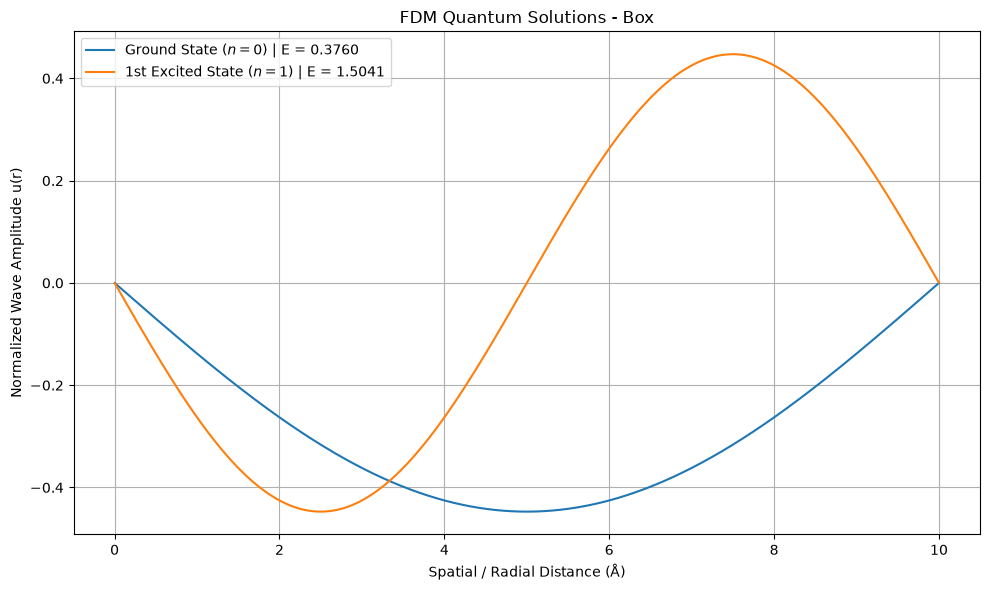

In [13]:
solver = FDMSolver(n=4000)
e0, e1 = solver.solve_case("box")
solver.plot_states()

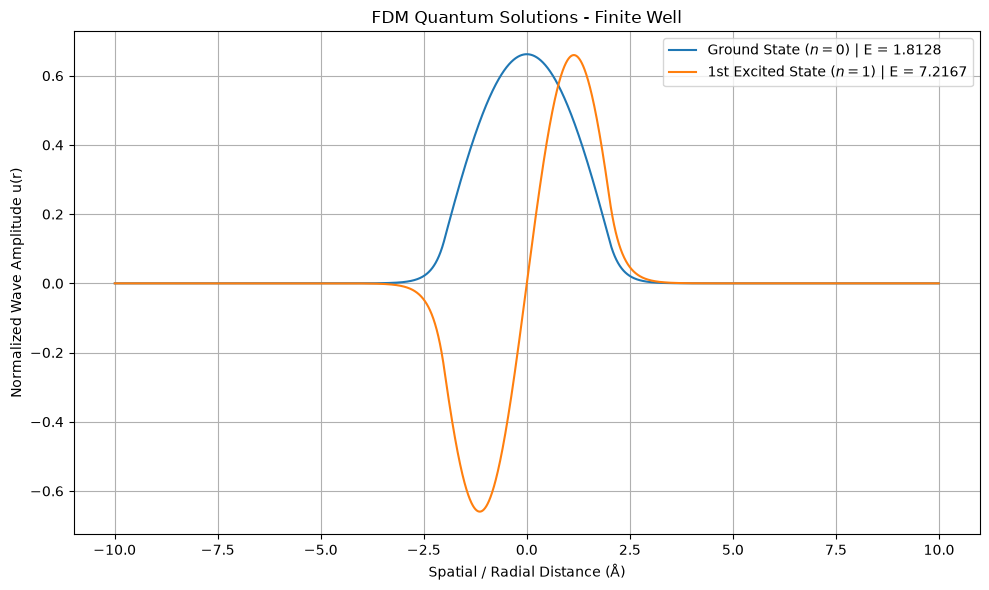

In [14]:
solver = FDMSolver(n=4000)
e0, e1 = solver.solve_case("finite_well")
solver.plot_states()

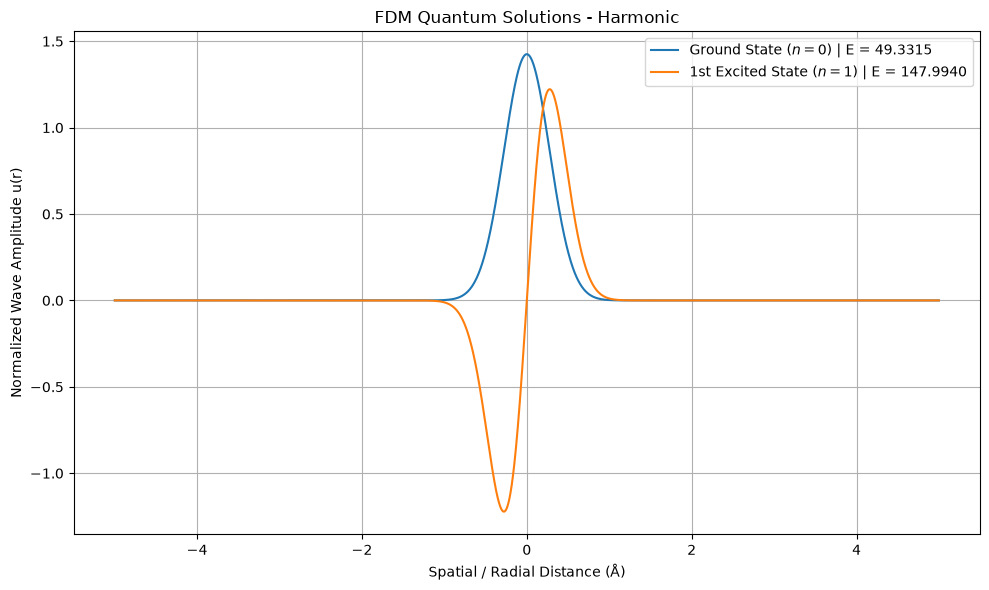

In [15]:
solver = FDMSolver(n=4000)
e0, e1 = solver.solve_case("harmonic")
solver.plot_states()

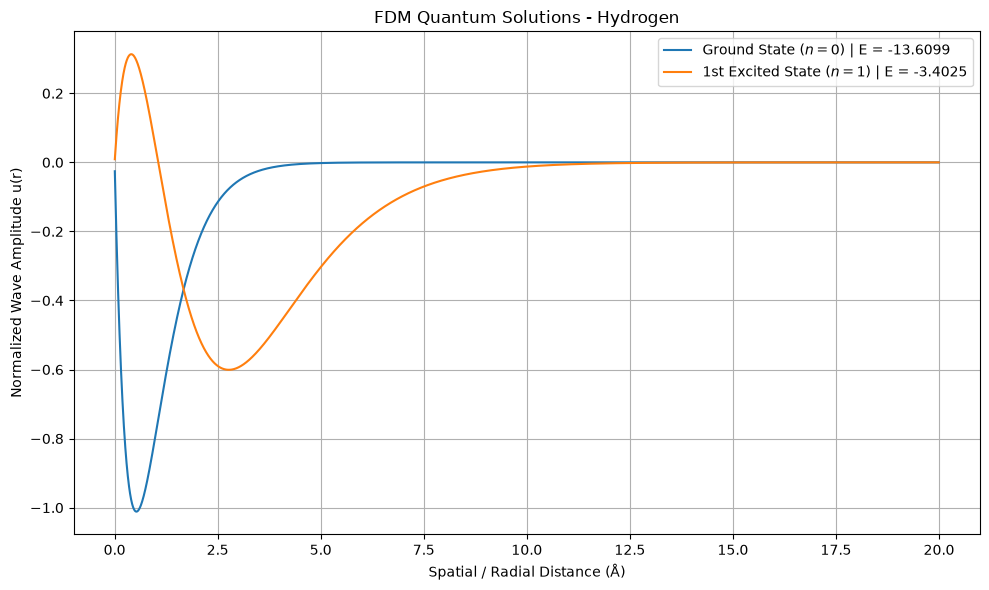

In [16]:
solver = FDMSolver(n=4000)
e0, e1 = solver.solve_case("hydrogen")
solver.plot_states()

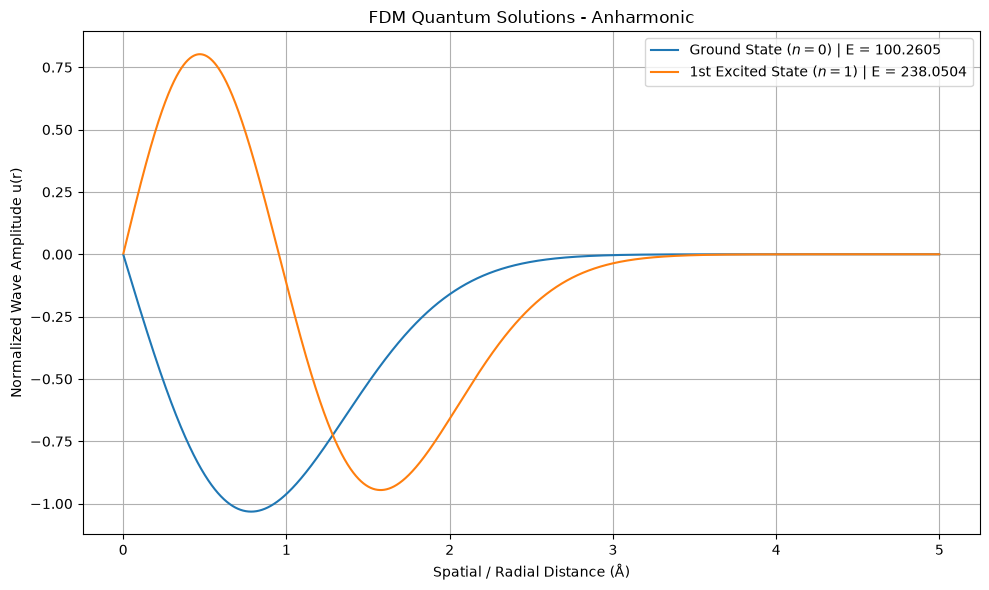

In [17]:
solver = FDMSolver(n=4000)
e0, e1 = solver.solve_case("anharmonic")
solver.plot_states()

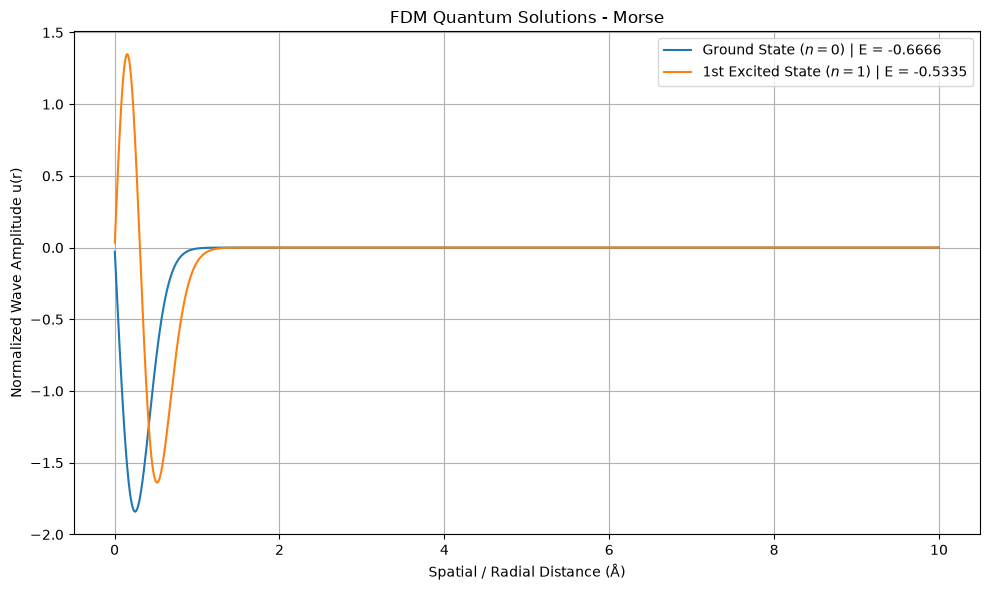

In [22]:
solver = FDMSolver(n=4000)
e0, e1 = solver.solve_case("morse")
solver.plot_states()

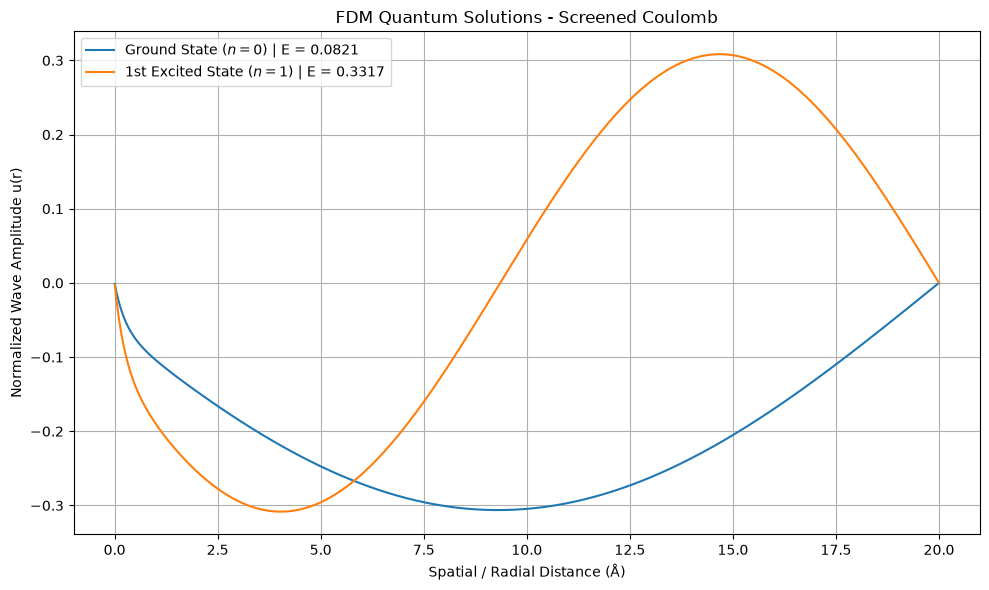

In [19]:
solver = FDMSolver(n=4000)
e0, e1 = solver.solve_case("screened_coulomb")
solver.plot_states()